In [1]:

"""Exploratory analysis of the Olist customer reviews dataset."""

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("../data/raw/olist_order_reviews_dataset.csv")


In [2]:

"""Load customer reviews and inspect the dataset structure."""

reviews = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {reviews.shape}")
display(reviews.head())
display(reviews.info())


Dataset shape: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB


None

In [3]:

"""Measure the availability of textual customer reviews."""

has_text = reviews["review_comment_message"].fillna("").str.strip().ne("")

summary = pd.DataFrame({
    "category": ["With text", "Without text"],
    "count": [has_text.sum(), (~has_text).sum()],
})

summary["percentage"] = (
    summary["count"] / len(reviews) * 100
).round(2)

display(summary)


,category,count,percentage
0,With text,40950,41.27
1,Without text,58274,58.73


,All reviews,Reviews with text
review_score,,
1,11424,8744
2,3151,2145
3,8179,3556
4,19142,5970
5,57328,20535


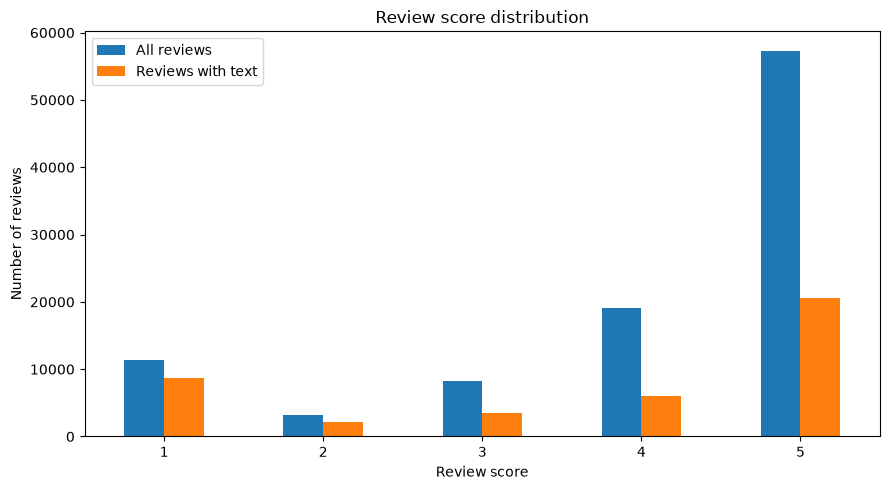

In [4]:

"""Compare review scores in the full dataset and textual reviews."""

score_distribution = pd.DataFrame({
    "All reviews": reviews["review_score"].value_counts().sort_index(),
    "Reviews with text": (
        reviews.loc[has_text, "review_score"]
        .value_counts()
        .sort_index()
    ),
})

display(score_distribution)

score_distribution.plot(kind="bar", figsize=(9, 5))
plt.title("Review score distribution")
plt.xlabel("Review score")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [5]:

"""Inspect comment lengths and potential duplicate records."""

text_reviews = reviews.loc[has_text].copy()
text_reviews["comment_length"] = (
    text_reviews["review_comment_message"].str.len()
)

display(
    text_reviews["comment_length"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

duplicate_summary = pd.Series({
    "Duplicate review IDs": reviews["review_id"].duplicated().sum(),
    "Exact duplicate rows": reviews.duplicated().sum(),
    "Duplicate non-empty comments": (
        text_reviews["review_comment_message"].duplicated().sum()
    ),
})

display(duplicate_summary)


count    40950.000000
mean        68.681245
std         53.840130
min          1.000000
50%         53.000000
90%        161.000000
95%        192.000000
99%        200.000000
max        208.000000
Name: comment_length, dtype: float64

Duplicate review IDs             814
Exact duplicate rows               0
Duplicate non-empty comments    4795
dtype: int64